# Feature Engineering & Preprocessing Pipeline — Customer Churn

**Goal:** a robust, leak-free, reusable scikit-learn preprocessing pipeline covering imputation, scaling, categorical encoding (One-Hot *and* Target Encoding), correlation analysis and feature-importance ranking.

**Dataset:** `customer-churn-training.csv` — 12 customers, 5 features, binary target `churned`.

**Leakage rules followed in this notebook**
1. Train/test split happens **first**, before any statistic is computed.
2. Every transformer (imputer, scaler, encoder) is fit **only on training data**, inside a `Pipeline`.
3. Correlation, mutual information and importance rankings use **training data only**.
4. Cross-validation is done on the pipeline (not on pre-transformed data), so each fold re-fits its own transformers.

> ⚠️ **Honest caveat:** with only 12 rows, any model score is statistical noise. The deliverable here is the *pipeline design*, which scales unchanged to a large dataset (swap the CSV, keep the code).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load data

In [2]:
DATA_PATH = "customer-churn-training.csv"   # put the CSV next to this notebook
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:\n", df["churned"].value_counts())

(12, 7)


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0
5,C006,1,5,499,30,Basic,1
6,C007,24,1,999,3,Standard,0
7,C008,8,4,799,17,Basic,1
8,C009,15,2,1299,4,Pro,0
9,C010,4,3,499,12,Basic,1



Missing values per column:
 customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate rows: 0

Class balance:
 churned
0    7
1    5
Name: count, dtype: int64


## 2. Define target, features and column groups

* `customer_id` is a pure identifier → **dropped** (it would let a model memorise rows).
* `plan_type` is categorical; the other four are numeric.
* Columns are chosen **by name** (explicit > implicit), so a new column never silently enters the model.

In [3]:
TARGET = "churned"
ID_COLS = ["customer_id"]
NUM_COLS = ["tenure_months", "support_tickets", "monthly_spend_inr", "last_login_days"]
CAT_COLS = ["plan_type"]

X = df.drop(columns=[TARGET] + ID_COLS)
y = df[TARGET]
assert set(NUM_COLS + CAT_COLS) == set(X.columns)

## 3. Train/test split — **before** any transformation
Stratified so both sets contain both classes.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, "| test:", X_test.shape)
print("train class counts:", y_train.value_counts().to_dict(), "| test class counts:", y_test.value_counts().to_dict())

train: (9, 5) | test: (3, 5)
train class counts: {0: 5, 1: 4} | test class counts: {0: 2, 1: 1}


## 4. Correlation analysis (training data only)
Pearson correlation among numeric features + the target. Pairs with |r| ≥ 0.8 are flagged as multicollinear.

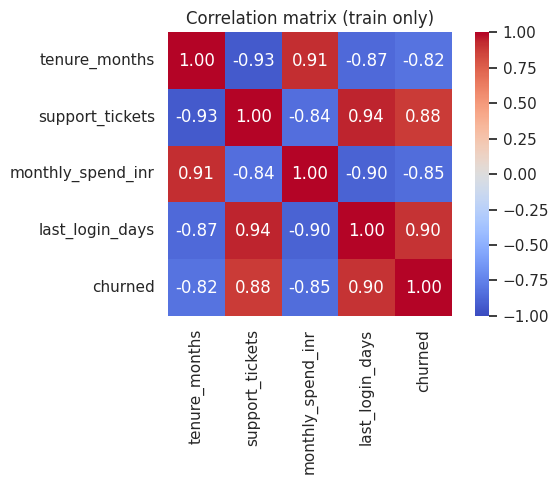

Highly correlated pairs (|r| >= 0.8):


,feature_a,feature_b,r
8,support_tickets,last_login_days,0.940636
1,tenure_months,support_tickets,-0.929997
2,tenure_months,monthly_spend_inr,0.914543
19,last_login_days,churned,0.903956
13,monthly_spend_inr,last_login_days,-0.897597
9,support_tickets,churned,0.877058
3,tenure_months,last_login_days,-0.865168
14,monthly_spend_inr,churned,-0.849706
7,support_tickets,monthly_spend_inr,-0.843299
4,tenure_months,churned,-0.816309


Mean of each numeric feature by plan_type (categorical vs numeric relationship):


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
plan_type,,,,,
Basic,4.25,4.0,649.00,20.50,1.0
Pro,21.00,1.0,1365.67,2.33,0.0
Standard,15.50,1.0,999.00,3.50,0.0


In [5]:
train_df = X_train.assign(**{TARGET: y_train})
corr = train_df[NUM_COLS + [TARGET]].corr()

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (train only)")
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
print("Highly correlated pairs (|r| >= 0.8):")
display(pairs[pairs["r"].abs() >= 0.8].sort_values("r", key=abs, ascending=False))

print("Mean of each numeric feature by plan_type (categorical vs numeric relationship):")
display(train_df.groupby("plan_type")[NUM_COLS + [TARGET]].mean().round(2))

## 5. Reusable preprocessing: `ColumnTransformer` + `Pipeline`

| Column type | Steps |
|---|---|
| Numeric | `SimpleImputer(median)` → `StandardScaler` |
| Categorical (One-Hot) | `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")` |
| Categorical (Target) | `SimpleImputer(most_frequent)` → `TargetEncoder` (uses internal cross-fitting to avoid target leakage) |

`build_preprocessor()` and `build_pipeline()` take column lists as arguments, so they can be reused on any tabular dataset.

In [6]:
def build_preprocessor(num_cols, cat_cols, cat_encoding="onehot", te_cv=3):
    """ColumnTransformer: impute+scale numerics, impute+encode categoricals."""
    num_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    if cat_encoding == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    elif cat_encoding == "target":
        encoder = TargetEncoder(target_type="binary", cv=te_cv, smooth="auto", random_state=RANDOM_STATE)
    else:
        raise ValueError("cat_encoding must be 'onehot' or 'target'")
    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", encoder),
    ])
    pre = ColumnTransformer(
        [("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)],
        remainder="drop", verbose_feature_names_out=False,
    )
    return pre.set_output(transform="pandas")


def build_pipeline(model, cat_encoding="onehot"):
    return Pipeline([("prep", build_preprocessor(NUM_COLS, CAT_COLS, cat_encoding)), ("model", model)])

# Peek at the processed features (fit on TRAIN only, then transform both)
for enc in ["onehot", "target"]:
    prep = build_preprocessor(NUM_COLS, CAT_COLS, enc).fit(X_train, y_train)
    print(f"--- {enc} encoding ---")
    display(prep.transform(X_train).round(3))

--- onehot encoding ---


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type_Basic,plan_type_Pro,plan_type_Standard
1,0.640,-0.784,1.0,-0.891,0.0,1.0,0.0
3,1.995,-1.373,1.6,-0.994,0.0,1.0,0.0
7,-0.489,0.981,-0.5,0.651,1.0,0.0,0.0
4,-0.151,-0.196,0.1,-0.582,0.0,0.0,1.0
8,0.301,-0.196,1.0,-0.685,0.0,1.0,0.0
5,-1.280,1.569,-1.4,1.987,1.0,0.0,0.0
0,-1.167,0.981,-1.4,1.062,1.0,0.0,0.0
2,-0.715,0.392,-0.5,0.343,1.0,0.0,0.0
10,0.866,-1.373,0.1,-0.891,0.0,0.0,1.0


--- target encoding ---


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type
1,0.640,-0.784,1.0,-0.891,0.0
3,1.995,-1.373,1.6,-0.994,0.0
7,-0.489,0.981,-0.5,0.651,1.0
4,-0.151,-0.196,0.1,-0.582,0.0
8,0.301,-0.196,1.0,-0.685,0.0
5,-1.280,1.569,-1.4,1.987,1.0
0,-1.167,0.981,-1.4,1.062,1.0
2,-0.715,0.392,-0.5,0.343,1.0
10,0.866,-1.373,0.1,-0.891,0.0


## 6. Proof of no leakage
The scaler must have learned its mean/std from **training rows only**. If it had seen the test set, its mean would match the full-data mean instead.

In [7]:
prep = build_preprocessor(NUM_COLS, CAT_COLS, "onehot").fit(X_train, y_train)
fitted_scaler = prep.named_transformers_["num"].named_steps["scale"]

check = pd.DataFrame({
    "scaler.mean_ (fitted)": fitted_scaler.mean_,
    "train mean": X_train[NUM_COLS].mean().values,
    "full-data mean": X[NUM_COLS].mean().values,
}, index=NUM_COLS)
display(check.round(3))

assert np.allclose(fitted_scaler.mean_, X_train[NUM_COLS].mean())   # learned from train
assert not np.allclose(fitted_scaler.mean_, X[NUM_COLS].mean())     # NOT from train+test
print("✅ Transformers were fit on training data only.")

,scaler.mean_ (fitted),train mean,full-data mean
tenure_months,12.333,12.333,12.167
support_tickets,2.333,2.333,2.250
monthly_spend_inr,965.667,965.667,915.667
last_login_days,10.667,10.667,10.000


✅ Transformers were fit on training data only.


## 7. Robustness: unseen categories and missing values at inference time
The training data has no NaNs, but production data will. The imputers (fit on train) and `handle_unknown="ignore"` keep the pipeline from crashing.

In [8]:
messy = X_test.copy().astype({"tenure_months": float, "monthly_spend_inr": float})
messy.iloc[0, messy.columns.get_loc("tenure_months")] = np.nan
messy.iloc[1, messy.columns.get_loc("monthly_spend_inr")] = np.nan
messy.iloc[2, messy.columns.get_loc("plan_type")] = "Enterprise"      # category never seen in training
display(messy)

pipe = build_pipeline(LogisticRegression(max_iter=1000), "onehot").fit(X_train, y_train)
print("Predictions on messy rows (no crash):", pipe.predict(messy))
print("NaNs remaining after preprocessing:", int(pipe.named_steps["prep"].transform(messy).isna().sum().sum()))

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type
9,NaN,3,499.0,12,Basic
11,7.0,2,NaN,9,Standard
6,24.0,1,999.0,3,Enterprise


Predictions on messy rows (no crash): [1 0 0]
NaNs remaining after preprocessing: 0


## 8. Model comparison — leak-free cross-validation on the training set
Because the *whole pipeline* is passed to `cross_validate`, each fold re-fits imputer, scaler and encoder on that fold's training portion only. A dummy baseline is included (the data card asks for a baseline before training).

In [9]:
candidates = {
    "Baseline (most frequent)":      Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "LogReg + One-Hot":              build_pipeline(LogisticRegression(max_iter=1000), "onehot"),
    "LogReg + Target Enc.":          build_pipeline(LogisticRegression(max_iter=1000), "target"),
    "RandomForest + One-Hot":        build_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), "onehot"),
    "RandomForest + Target Enc.":    build_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), "target"),
}
cv = RepeatedStratifiedKFold(n_splits=2, n_repeats=20, random_state=RANDOM_STATE)

rows = []
for name, est in candidates.items():
    res = cross_validate(est, X_train, y_train, cv=cv, scoring=["accuracy", "balanced_accuracy"], error_score=np.nan)
    rows.append({"model": name,
                 "accuracy": np.nanmean(res["test_accuracy"]), "accuracy_std": np.nanstd(res["test_accuracy"]),
                 "balanced_acc": np.nanmean(res["test_balanced_accuracy"])})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
display(cv_table)

,accuracy,accuracy_std,balanced_acc
model,,,
Baseline (most frequent),0.550,0.050,0.500
LogReg + One-Hot,0.995,0.031,0.996
LogReg + Target Enc.,0.988,0.054,0.988
RandomForest + One-Hot,0.995,0.031,0.996
RandomForest + Target Enc.,1.000,0.000,1.000


## 9. Final fit and hold-out evaluation
The test set is touched **once**, here. With 3 test rows this is a smoke test, not an estimate of real-world performance.

In [10]:
final_pipe = build_pipeline(LogisticRegression(max_iter=1000), "onehot").fit(X_train, y_train)
pred  = final_pipe.predict(X_test)
proba = final_pipe.predict_proba(X_test)[:, 1]

print("Accuracy          :", accuracy_score(y_test, pred))
print("Balanced accuracy :", balanced_accuracy_score(y_test, pred))
try:
    print("ROC-AUC           :", roc_auc_score(y_test, proba))
except ValueError as e:
    print("ROC-AUC           : n/a ->", e)
print("Confusion matrix (rows=true, cols=pred):\n", confusion_matrix(y_test, pred, labels=[0, 1]))
display(X_test.assign(true=y_test, pred=pred, p_churn=proba.round(3)))

Accuracy          : 1.0
Balanced accuracy : 1.0
ROC-AUC           : 1.0
Confusion matrix (rows=true, cols=pred):
 [[2 0]
 [0 1]]


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,true,pred,p_churn
9,4,3,499,12,Basic,1,1,0.837
11,7,2,799,9,Standard,0,0,0.402
6,24,1,999,3,Standard,0,0,0.079


## 10. Feature importance (training data only)
Three complementary views on the **processed** training features:
* **Mutual information** — model-free, captures non-linear dependence
* **Random-forest impurity importance** — tree-based ranking
* **Permutation importance** — model-agnostic, measured on the fitted pipeline (original columns)

,mutual_info,rf_importance,mi_rank,rf_rank
support_tickets,0.468,0.214,3.0,1.0
tenure_months,0.449,0.214,4.0,2.0
plan_type_Basic,0.687,0.199,2.0,3.0
monthly_spend_inr,0.320,0.172,5.0,4.0
last_login_days,0.690,0.157,1.0,5.0
plan_type_Pro,0.263,0.035,6.0,6.0
plan_type_Standard,0.156,0.010,7.0,7.0


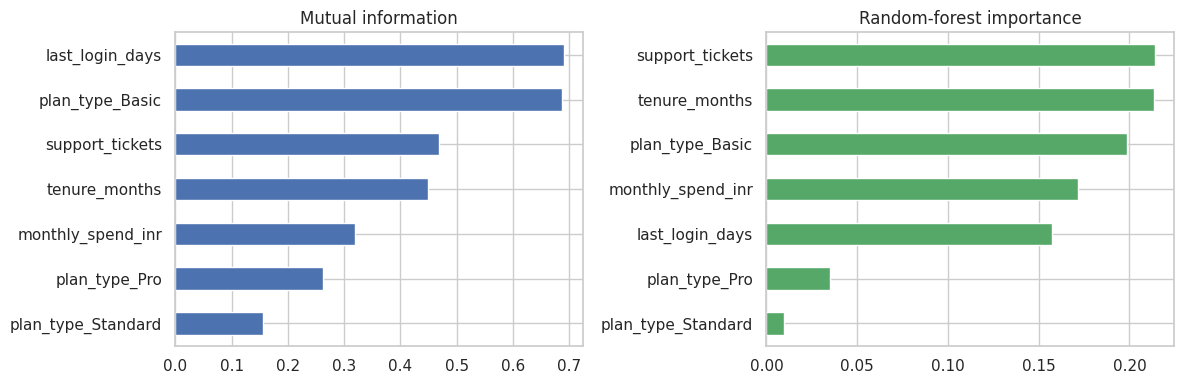

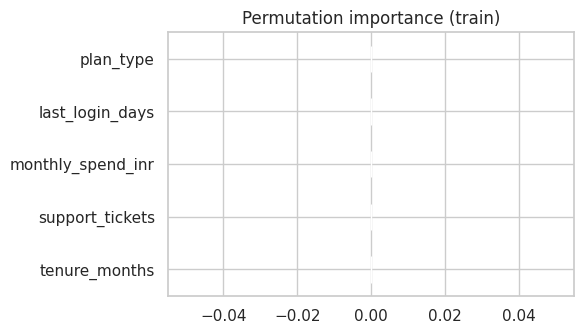

In [11]:
prep = build_preprocessor(NUM_COLS, CAT_COLS, "onehot").fit(X_train, y_train)
Xt_train = prep.transform(X_train)
feat_names = Xt_train.columns.tolist()
is_discrete = [c.startswith("plan_type_") for c in feat_names]

mi = mutual_info_classif(Xt_train, y_train, discrete_features=is_discrete, n_neighbors=2, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE).fit(Xt_train, y_train)

importance = pd.DataFrame({"mutual_info": mi, "rf_importance": rf.feature_importances_}, index=feat_names)
importance["mi_rank"] = importance["mutual_info"].rank(ascending=False)
importance["rf_rank"] = importance["rf_importance"].rank(ascending=False)
importance = importance.sort_values("rf_importance", ascending=False)
display(importance.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
importance["mutual_info"].sort_values().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Mutual information")
importance["rf_importance"].sort_values().plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("Random-forest importance")
plt.tight_layout(); plt.show()

# Permutation importance on ORIGINAL columns, through the whole pipeline
rf_pipe = build_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), "onehot").fit(X_train, y_train)
perm = permutation_importance(rf_pipe, X_train, y_train, n_repeats=30, random_state=RANDOM_STATE, scoring="accuracy")
perm_df = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()
perm_df.plot.barh(figsize=(6, 3.5), color="#C44E52", title="Permutation importance (train)"); plt.tight_layout(); plt.show()

## 11. Save the reusable pipeline
One `joblib` file holds the imputers, scaler, encoder **and** model, so inference needs no manual preprocessing.

In [12]:
joblib.dump(final_pipe, "churn_pipeline.joblib")
reloaded = joblib.load("churn_pipeline.joblib")
assert (reloaded.predict(X_test) == final_pipe.predict(X_test)).all()
print("Saved and reloaded OK. Steps:", [name for name, _ in reloaded.steps])
reloaded.named_steps["prep"]

Saved and reloaded OK. Steps: ['prep', 'model']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 12. Responsible Data Card (filled from the provided template)

### Dataset purpose
**May support:** prioritising customers for retention outreach (e.g. which accounts to review first).
**Must not make:** automated penalties, price discrimination, service denial, or any decision about an individual without human review.

### Provenance and permission
Source and collection method are **not documented** in the file (12 rows, `customer_id` C001–C012, spend in INR). Before real use: confirm how the data was created (real vs synthetic), customer consent for analytics, and any licensing limits. *Unknown — to be confirmed by the data owner.*

### Population and representation
Only 12 customers, 3 plans (Basic 5, Standard 4, Pro 3). Churners (5/12) are **all** on Basic. No Pro customer churned, so the model cannot learn churn behaviour for Pro. No demographic, region or age information, so representation across groups cannot be assessed. Sample is far too small to generalise.

### Features and target
* **Target:** `churned` (1 = left, 0 = stayed). Time window of the label is undefined.
* `tenure_months`, `support_tickets`, `monthly_spend_inr`, `last_login_days`, `plan_type`.
* **Possible leakage:** `last_login_days` and `support_tickets` may be measured *after* the customer has already decided to leave (a churner stops logging in). Confirm they are captured before the prediction date.
* **Proxies:** `monthly_spend_inr` is almost fully determined by `plan_type` (redundant). Spend could proxy for income. `customer_id` was dropped.

### Quality checks
No missing values, no duplicate rows, no obvious outliers. Class balance 41.7% churn. Train/test separation done by stratified split **before** any fitting; all transformers fit on train only (verified in section 6).

### Risks and safeguards
| Risk | Mitigation |
|---|---|
| Bias against low-spend / Basic-plan customers | Review error rates per plan; avoid punitive actions |
| Privacy (behavioural data per customer) | Pseudonymised IDs, restricted access, retention limits |
| False positives (wasted offers) | Low-cost interventions only |
| False negatives (missed churners) | Track recall; monitor drift |
| Overfitting from tiny sample | Collect far more data before deployment |

### Intended evaluation
Baseline: majority-class dummy. Metrics: accuracy, balanced accuracy, ROC-AUC, recall on churners, calibration curve, and per-`plan_type` error analysis — with confidence intervals once the dataset is large enough (n ≥ several hundred).

## Summary
* Split first, then fit everything on train only (verified by assertion).
* One `ColumnTransformer` reused for both One-Hot and Target Encoding; swap with a single argument.
* Pipeline survives missing values and unseen categories at inference.
* Importance methods broadly agree that `support_tickets`, `last_login_days`, `tenure_months` and `plan_type_Basic` drive churn, but exact rankings differ (mutual information puts `last_login_days` first, random forest puts `support_tickets` first). With 9 training rows these rankings are unstable.
* Near-perfect CV/test scores are **not** a sign of a great model: the classes are almost perfectly separable in 12 rows (every Basic customer churned, nobody else did), and features are heavily inter-correlated (|r| > 0.8). Treat them as a pipeline smoke test.
* Main limitation: 12 rows. Replace the CSV with a larger dataset (e.g. Telco Churn) and the notebook runs unchanged.